# 3. Conditions géographiques : altitude, roche, profondeur

Le niveau d'une nappe dépend de trois choses : la **géographie** (altitude, roche, profondeur de l'ouvrage), la **pluie** et l'**industrie**.
Avant de chercher l'effet de l'industrie, on regarde si la géographie suffit à expliquer les **variations** des nappes :
si deux nappes de même roche ou de même profondeur bougeaient de la même façon, il faudrait comparer les stations à géographie égale.

On se restreint aux stations bien suivies sur 2015-2025 (au moins 80 % des mois mesurés), les mêmes que dans la partie climat.

Ce notebook étudie l'effet de l'altitude, de la roche et de la profondeur.

Variables produites : `MOIS`, `niveaux_mensuels`, `suivies`, et dans `stations` les colonnes `amplitude`, `niveau_moyen`, `nappe_captive`, `famille_geol`, `classe_profondeur`.


In [1]:
%%capture
#Étapes précédentes : exécutées sans afficher leurs figures ni leurs messages, et une seule fois par noyau
#(si les données ne sont pas encore en cache, exécuter d'abord eau_01_donnees.ipynb seul pour suivre le téléchargement)
AFFICHER = globals().get("AFFICHER", True)   #True si ce notebook est ouvert seul, False s'il est appelé par un autre notebook
_afficher_etape_03, AFFICHER = AFFICHER, False
if "ETAPE_01" not in globals():
    %run ./donnees.ipynb
AFFICHER = _afficher_etape_03
plt.close("all")

In [2]:
#Niveau mensuel par station sur 2015-2025 : on garde les stations mesurées au moins 80 % des mois
MOIS = pd.date_range("2015-01-01", "2025-12-01", freq="MS")   #Les 132 mois de l'étude, datés du 1er du mois (MS = Month Start)
niveaux_mensuels = chroniques_niveau_mensuel.pivot(index="date_mesure", columns="code_bss", values="niveau_nappe_eau")
niveaux_mensuels = niveaux_mensuels.reindex(MOIS)   #Un mois sans mesure devient une ligne vide (NaN) au lieu de disparaître et les eventuels mois hors période disparaissent

part_mois_mesures = niveaux_mensuels.notna().mean()   
# Moyenne des 1 et 0 selon s'il y a une valeur : donne la proportion des mesures présentes
# C'est une série qui pour chaque code_bss donne une proportion

niveaux_mensuels = niveaux_mensuels.loc[:, part_mois_mesures >= 0.8]
# On garde toutes les lignes des colonnes qui ont au moins 80% de valeurs non Nan


# On comble les trous par interpolation linéaire, seulement entre deux mesures et sur 2 mois d'affilée au plus
# (dans un trou plus long, seuls les 2 premiers mois sont comblés, les suivants restent vides)
# Justifié car le niveau d'eau d'une nappe varie lentement
niveaux_mensuels = niveaux_mensuels.interpolate(limit=2, limit_area="inside")

#Variation de chaque station : amplitude max - min sur 2015-2025 (en mètres, directement lisible ; l'écart-type donne les mêmes conclusions)
stations["amplitude"] = stations["code_bss"].map(niveaux_mensuels.max() - niveaux_mensuels.min())   #NaN pour les stations écartées par le filtre
stations["amplitude"].describe().round(2)

count    45.00
mean      3.82
std       2.91
min       0.96
25%       2.23
50%       2.61
75%       3.95
max      17.62
Name: amplitude, dtype: float64

## 3.1 Altitude

Commençons par un état des lieux de l'altitude des différentes stations.

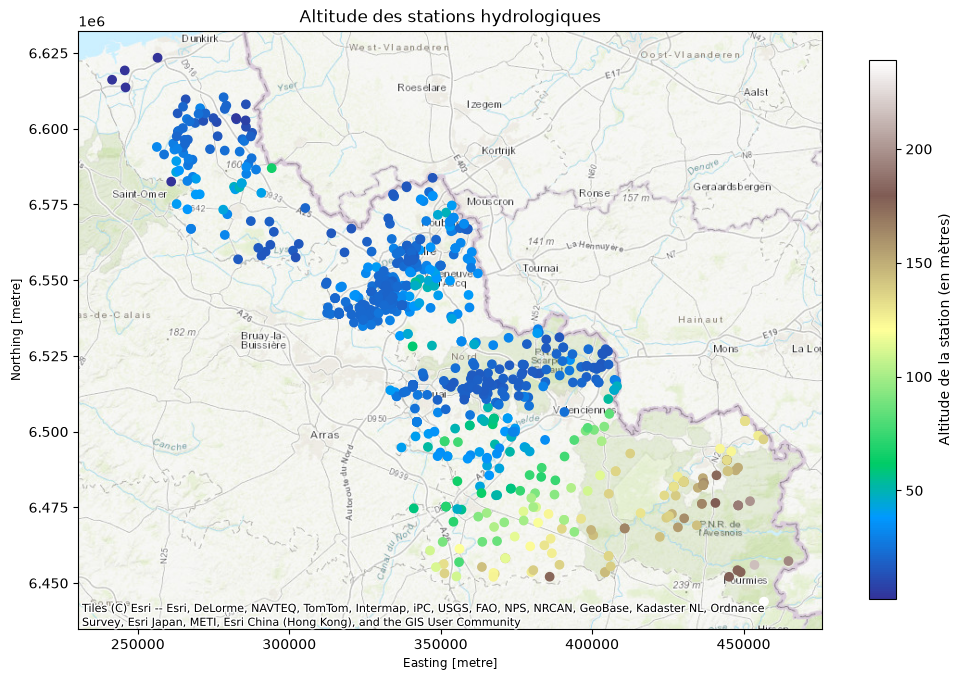

In [3]:
stations['altitude_station'] = pd.to_numeric(stations['altitude_station'])

def fig_carte_altitude():
    """Carte des stations colorées selon leur altitude."""
    points_carte = stations.to_crs(epsg=3857)   #on transforme le geopandas avec le code EPSG utilisé par les cartes et Google

    fig, ax = plt.subplots(figsize=(12, 10))
    points_carte.plot(ax=ax,
        column='altitude_station', # variable qui donne la couleur du point
        cmap='terrain', # palette de couleurs adaptée à la topographie
        legend=True,                 # Affichage de la barre de gradient
        legend_kwds={
            'label': "Altitude de la station (en mètres)",
            'shrink': 0.7   #Limite la taille de la barre de la légende
        },
        zorder=2
    )
    ctx.add_basemap(ax, source=ctx.providers.Esri.WorldTopoMap, zorder=1)   #Fond de carte
    plt.title("Altitude des stations hydrologiques")
    plt.show()

if AFFICHER:
    fig_carte_altitude()

`niveau_nappe_eau` est une altitude (en m NGF, par rapport au niveau de la mer), pas une hauteur au-dessus du fond de la nappe : on ne peut pas obtenir le volume d'eau dans la nappe, seulement observer son niveau. Une station haut perchée a donc une nappe haute.  
Pour comparer des stations d'altitudes différentes, la suite de l'analyse étudie les **variations** du niveau de chaque station (amplitude, évolution entre deux périodes, tendance) plutôt que le niveau lui-même.  
On regarde d'abord le niveau moyen, puis l'amplitude.

In [4]:
#Niveau moyen de chaque station (en m NGF, sur toutes ses mesures mensuelles)
#map garde toutes les stations : celles sans chronique ont simplement un niveau moyen vide (NaN), aucune station n'est perdue
stations["niveau_moyen"] = stations["code_bss"].map(chroniques_niveau_mensuel.groupby("code_bss")["niveau_nappe_eau"].mean())

#Dans le Nord, une nappe libre ne descend pas sous le niveau de la mer : un niveau moyen négatif signale une nappe captive rabattue par les pompages
stations["nappe_captive"] = stations["niveau_moyen"] < 0

print(stations["nappe_captive"].sum(), "stations ont un niveau moyen sous le niveau de la mer :")
print(stations.loc[stations["nappe_captive"], ["code_bss", "nom_commune", "profondeur_investigation", "niveau_moyen"]])

4 stations ont un niveau moyen sous le niveau de la mer :
           code_bss        nom_commune  profondeur_investigation  niveau_moyen
207   00143A0008/F1          Linselles                    168.00    -62.624244
243   00143C0079/F1            Bondues                    168.53    -62.175621
369  00134X0127/PZ1             Nieppe                     55.00     -5.716221
667    BSS002PZXU/P  Quesnoy-sur-Deûle                    149.50    -46.868626


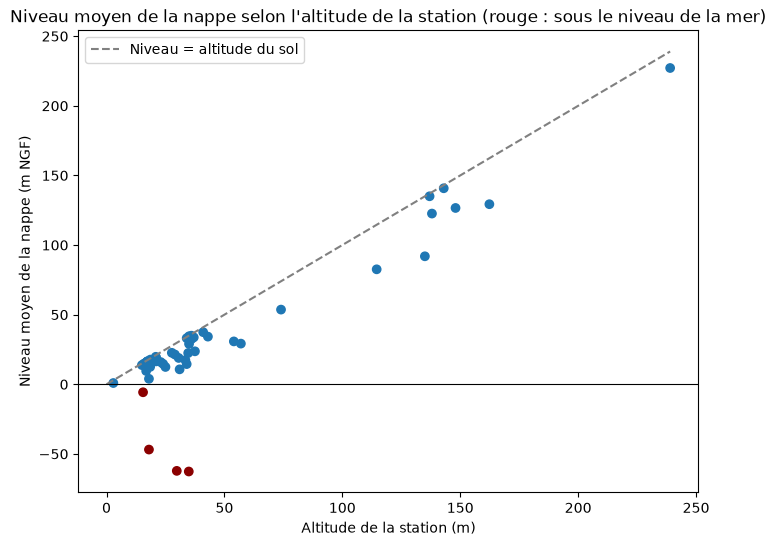

In [5]:
def fig_niveau_altitude():
    """Niveau moyen de la nappe selon l'altitude de la station, nappes captives en rouge."""
    plt.figure(figsize=(8, 6))
    plt.scatter(stations["altitude_station"], stations["niveau_moyen"], c=stations["nappe_captive"].map({True: "darkred", False: "tab:blue"}))   #Les stations sans mesure (NaN) ne sont pas tracées
    plt.plot([0, stations["altitude_station"].max()], [0, stations["altitude_station"].max()], color="grey", linestyle="--", label="Niveau = altitude du sol")
    plt.axhline(0, color="black", linewidth=0.8)
    plt.legend()
    plt.title("Niveau moyen de la nappe selon l'altitude de la station (rouge : sous le niveau de la mer)")
    plt.xlabel("Altitude de la station (m)")
    plt.ylabel("Niveau moyen de la nappe (m NGF)")
    plt.show()

if AFFICHER:
    fig_niveau_altitude()

Le niveau moyen suit l'altitude : la nappe est en général à quelques mètres sous le sol. Les exceptions, sous le niveau de la mer, sont des nappes **captives**
(enfermées sous une couche imperméable) rabattues par des décennies de pompages : le calcaire carbonifère au nord de Lille (vers -60 m NGF) et les sables du Landénien
sous l'argile des Flandres (Nieppe). On les repère avec la colonne `nappe_captive` **sans les écarter** : leur baisse peut justement venir des prélèvements,
industriels compris, ce que l'on cherche à mesurer.

L'altitude fixe donc le niveau moyen. Fixe-t-elle aussi l'ampleur des variations ?

Corrélation de Spearman entre altitude et amplitude : rho = 0.48 (p = 0.001)


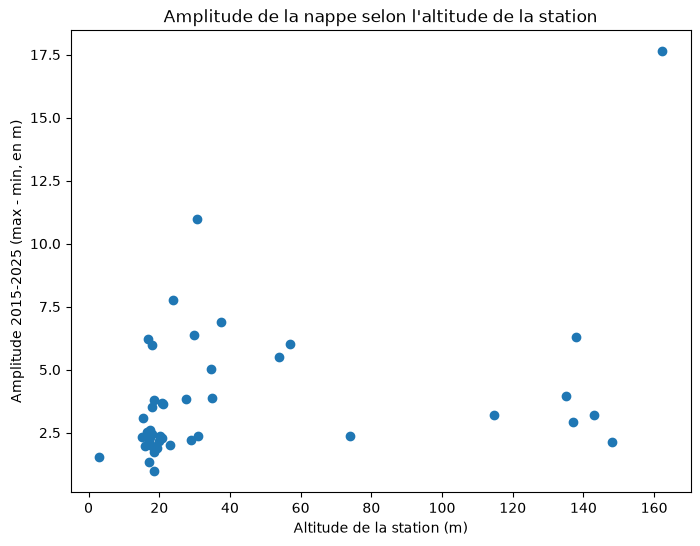

In [6]:
#Corrélation de rang (Spearman) : ne suppose pas un lien linéaire et résiste aux quelques stations extrêmes ; nan_policy ignore les stations sans amplitude
rho, p = spearmanr(stations["altitude_station"], stations["amplitude"], nan_policy="omit")
print(f"Corrélation de Spearman entre altitude et amplitude : rho = {rho:.2f} (p = {p:.3f})")

def fig_amplitude_altitude():
    """Amplitude 2015-2025 de chaque station selon son altitude."""
    plt.figure(figsize=(8, 6))
    plt.scatter(stations["altitude_station"], stations["amplitude"])
    plt.title("Amplitude de la nappe selon l'altitude de la station")
    plt.xlabel("Altitude de la station (m)")
    plt.ylabel("Amplitude 2015-2025 (max - min, en m)")
    plt.show()

if AFFICHER:
    fig_amplitude_altitude()

**Lecture.** À première vue, l'amplitude monte avec l'altitude : la corrélation de Spearman est positive et significative (**ρ = 0,48**, p = 0,001, sur 45 stations).
Mais le nuage n'a pas la forme d'une tendance : les faibles amplitudes (2 à 2,5 m) sont presque toutes serrées entre 15 et 20 m d'altitude,
et au-delà de 100 m on trouve aussi bien 2 m que 17,6 m. Ce paquet de points bas est un groupe de stations particulier, que la roche permet d'identifier (3.2) :
on refait la corrélation sans lui en 3.3.

## 3.2 Roche

La roche pourrait changer la façon dont la nappe réagit : la craie, épaisse et poreuse, a une forte inertie, un sable superficiel réagit vite.
On classe les stations par famille géologique (`famille_geol`, d'après la masse d'eau) et, pour la partie 3.3, par classe de profondeur de l'ouvrage (`classe_profondeur`).

In [7]:
#Famille géologique d'après le nom de la masse d'eau (une liste depuis la cellule de chargement : une station peut en croiser plusieurs, on les met bout à bout)
noms_nappes = stations["noms_masse_eau_edl"].str.join(" + ")
#Le calcaire carbonifère passe en premier : une station qui le croise sous la craie mesure en fait le carbonifère (niveau très négatif)
stations["famille_geol"] = np.select(
    [noms_nappes.str.contains("carbonifère", na=False),
     noms_nappes.str.contains("Craie", na=False),
     noms_nappes.str.contains("Sables", na=False),
     noms_nappes.str.contains("Calcaire", na=False),
     noms_nappes.str.contains("Socle", na=False)],
    ["Calcaire carbonifère", "Craie", "Sables du Landénien", "Calcaires de l'Avesnois", "Socle ardennais"],
    default="Non renseignée")

#Profondeur de l'ouvrage (pas celle de l'eau) : un forage profond capte en général une nappe plus inerte
stations["classe_profondeur"] = pd.cut(stations["profondeur_investigation"], bins=[0, 30, 80, np.inf],
                                       labels=["1. superficielle (< 30 m)", "2. intermédiaire (30-80 m)", "3. profonde (> 80 m)"])

#Répartition des stations qui ont des mesures (les autres n'entrent pas dans la suite)
avec_mesures = stations.loc[stations["niveau_moyen"].notna()]
pd.crosstab(avec_mesures["famille_geol"], avec_mesures["classe_profondeur"], margins=True, margins_name="Total")

classe_profondeur,1. superficielle (< 30 m),2. intermédiaire (30-80 m),3. profonde (> 80 m),Total
famille_geol,,,,
Calcaire carbonifère,0,0,9,9
Calcaires de l'Avesnois,0,1,2,3
Craie,17,9,0,26
Non renseignée,16,0,0,16
Sables du Landénien,3,1,1,5
Socle ardennais,0,1,0,1
Total,36,12,12,60


La craie domine. Les 16 stations « Non renseignée » sont des piézomètres de 5 à 8 m de profondeur de la plaine de la Scarpe (Marchiennes, Vred, Rieulay...),
sans masse d'eau dans Hub'eau : ce sont des nappes superficielles, que l'on garde dans leur propre groupe plutôt que de leur inventer une roche.
Les deux classements se recoupent fortement (le calcaire carbonifère est toujours profond, la craie jamais au-delà de 80 m) et les effectifs par case sont petits :
on comparera par famille **ou** par classe de profondeur, pas les deux à la fois.

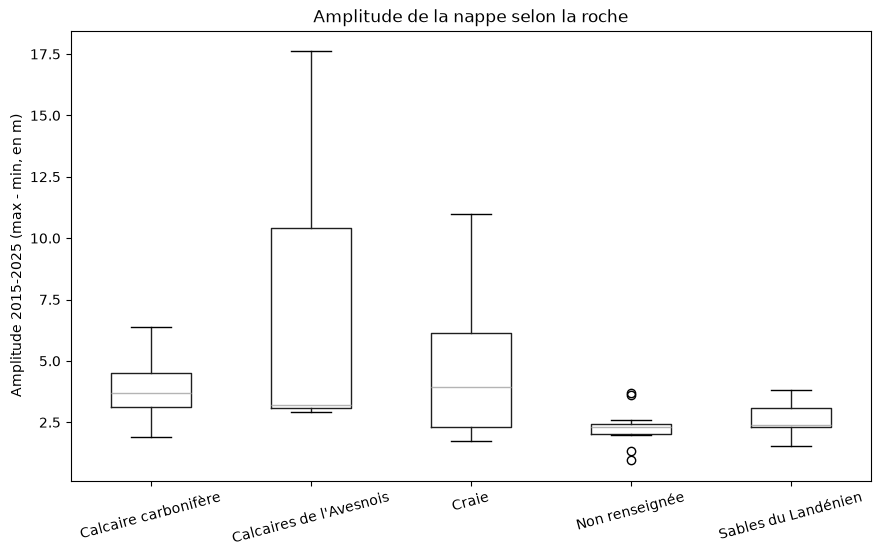

,nb_stations,mediane,minimum,maximum
famille_geol,,,,
Calcaire carbonifère,4,3.71,1.89,6.36
Calcaires de l'Avesnois,3,3.22,2.93,17.62
Craie,19,3.95,1.75,10.99
Non renseignée,14,2.31,0.96,3.68
Sables du Landénien,5,2.37,1.55,3.80


In [8]:
#Seulement les stations suivies sur 2015-2025 (celles qui ont une amplitude)
suivies = stations.dropna(subset=["amplitude"])
amplitude_par_roche = suivies.groupby("famille_geol")["amplitude"].agg(nb_stations="count", mediane="median", minimum="min", maximum="max").round(2)

def fig_amplitude_roche():
    """Boîtes à moustaches de l'amplitude 2015-2025 par famille géologique."""
    suivies.boxplot(column="amplitude", by="famille_geol", grid=False, rot=15, figsize=(10, 6))
    plt.title("Amplitude de la nappe selon la roche")
    plt.suptitle("")   #Sinon pandas ajoute un sous-titre automatique
    plt.xlabel("")
    plt.ylabel("Amplitude 2015-2025 (max - min, en m)")
    plt.show()

if AFFICHER:
    fig_amplitude_roche()
amplitude_par_roche

**Lecture.** Les médianes vont de **2,3 m** (« Non renseignée ») à **3,9 m** (craie), mais l'écart *à l'intérieur* d'une roche est bien plus grand qu'entre roches :
dans la craie, l'amplitude va de **1,7 m à 11 m** (19 stations), dans les calcaires de l'Avesnois de 2,9 à 17,6 m. Les autres familles n'ont que 3 à 5 stations, trop peu pour les départager.
Le seul groupe nettement à part est « Non renseignée » : les **14 piézomètres** de 5 à 8 m de la plaine de la Scarpe, tous sous 3,7 m d'amplitude.
Une nappe superficielle de plaine humide est drainée par les cours d'eau et les fossés dès qu'elle monte, elle reste donc dans une fourchette étroite (hypothèse non vérifiée).

## 3.3 Profondeur

Un forage profond capte en général une nappe plus inerte, un piézomètre de quelques mètres une nappe qui réagit vite.
On trace l'amplitude selon la profondeur de l'ouvrage, en distinguant les piézomètres de la Scarpe (famille « Non renseignée »).

profondeur_investigation : rho = 0.40 (p = 0.007) sur 45 stations, rho = 0.09 (p = 0.624) sans la Scarpe (31 stations)
altitude_station : rho = 0.48 (p = 0.001) sur 45 stations, rho = 0.32 (p = 0.077) sans la Scarpe (31 stations)


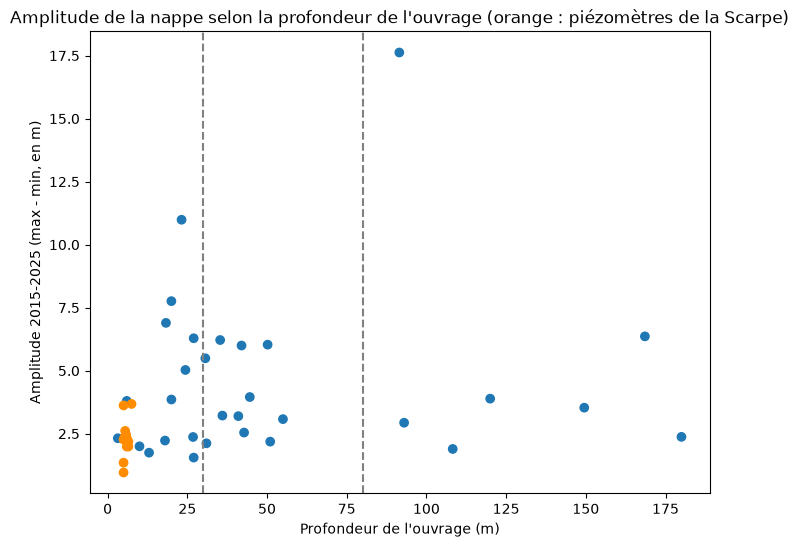

,nb_stations,mediane
classe_profondeur,,
1. superficielle (< 30 m),27,2.33
2. intermédiaire (30-80 m),11,3.22
3. profonde (> 80 m),7,3.53


In [9]:
#Même corrélation avec et sans les piézomètres de la Scarpe, pour la profondeur et pour l'altitude (vue en 3.1)
hors_scarpe = suivies[suivies["famille_geol"] != "Non renseignée"]
lignes_corr = []
for colonne in ["profondeur_investigation", "altitude_station"]:
    rho, p = spearmanr(suivies[colonne], suivies["amplitude"])
    rho_hs, p_hs = spearmanr(hors_scarpe[colonne], hors_scarpe["amplitude"])
    print(f"{colonne} : rho = {rho:.2f} (p = {p:.3f}) sur {len(suivies)} stations, rho = {rho_hs:.2f} (p = {p_hs:.3f}) sans la Scarpe ({len(hors_scarpe)} stations)")
    lignes_corr.append({"variable": colonne,
                        f"rho ({len(suivies)} stations)": round(rho, 2), "p": round(p, 3),
                        f"rho sans la Scarpe ({len(hors_scarpe)} stations)": round(rho_hs, 2), "p sans la Scarpe": round(p_hs, 3)})
correlations_amplitude = pd.DataFrame(lignes_corr).set_index("variable")

amplitude_par_profondeur = suivies.groupby("classe_profondeur", observed=True)["amplitude"].agg(nb_stations="count", mediane="median").round(2)

def fig_amplitude_profondeur():
    """Amplitude selon la profondeur de l'ouvrage, piézomètres de la Scarpe en orange."""
    plt.figure(figsize=(8, 6))
    plt.scatter(suivies["profondeur_investigation"], suivies["amplitude"], c=(suivies["famille_geol"] == "Non renseignée").map({True: "darkorange", False: "tab:blue"}))
    plt.axvline(30, color="grey", linestyle="--")   #Seuils de classe_profondeur
    plt.axvline(80, color="grey", linestyle="--")
    plt.title("Amplitude de la nappe selon la profondeur de l'ouvrage (orange : piézomètres de la Scarpe)")
    plt.xlabel("Profondeur de l'ouvrage (m)")
    plt.ylabel("Amplitude 2015-2025 (max - min, en m)")
    plt.show()

if AFFICHER:
    fig_amplitude_profondeur()
amplitude_par_profondeur

**Lecture.** Sur les 45 stations, l'amplitude augmente avec la profondeur (**ρ = 0,40**, p = 0,007) et la médiane passe de 2,3 m (superficielles) à 3,2 m puis 3,5 m.
Mais ce lien tient entièrement aux piézomètres de la Scarpe (en orange), tous à moins de 8 m et peu variables : sans eux, la corrélation tombe à **ρ = 0,09** (p = 0,62).
Parmi les ouvrages de moins de 30 m, on trouve d'ailleurs à la fois les plus petites amplitudes et l'une des plus grandes (11 m à Lille).
Même chose pour l'altitude vue en 3.1 : sans la Scarpe, ρ = 0,32 (p = 0,08), ce n'est plus significatif au seuil de 5 %.

## Conclusion partielle

La géographie fixe le **niveau moyen** d'une nappe : il suit l'altitude, sauf pour les 4 nappes captives rabattues sous le niveau de la mer.
Elle n'explique pas, en revanche, l'ampleur de ses **variations** : à roche ou profondeur égale, une station peut varier de 2 m comme de 11 m,
et les corrélations avec l'altitude et la profondeur disparaissent dès que l'on met à part un seul groupe homogène, les piézomètres superficiels de la Scarpe, qui varient moins que les autres.

Ces variations viennent d'abord de la météo : les saisons, puis les années sèches et la recharge record de 2023-2024.
L'amplitude mélange cette part climatique et une éventuelle baisse de fond, celle que l'on cherche : la partie suivante retire donc d'abord l'effet de la pluie.

In [10]:
#Marqueur : cette étape est faite, les notebooks qui en dépendent ne la relanceront pas dans ce noyau
ETAPE_03 = True